PCA scree+2D+3D; t-SNE perplexity sweep; UMAP hyperparameter grid; Isolation Forest vs IsAnomaly ground truth;
dim_reduction_dashboard() PNG

Dataset shape: (530, 10)
Normal observations: 500
True anomalies: 30


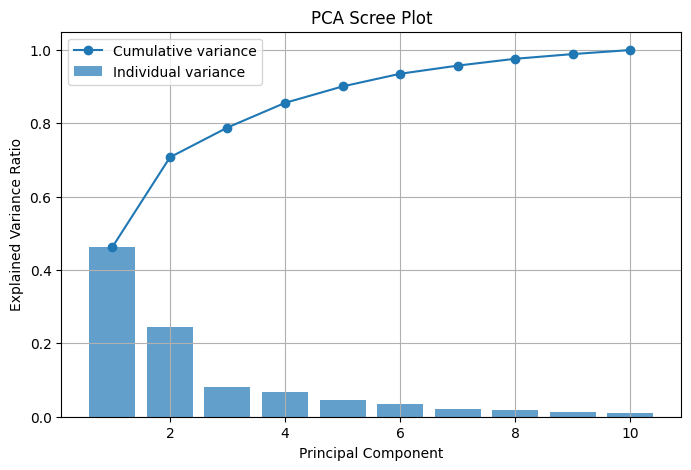

Variance explained by first 2 PCs: 70.76 %
Variance explained by first 3 PCs: 78.88 %


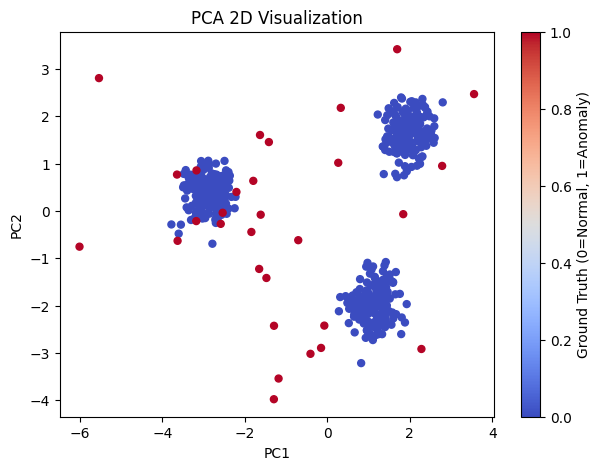

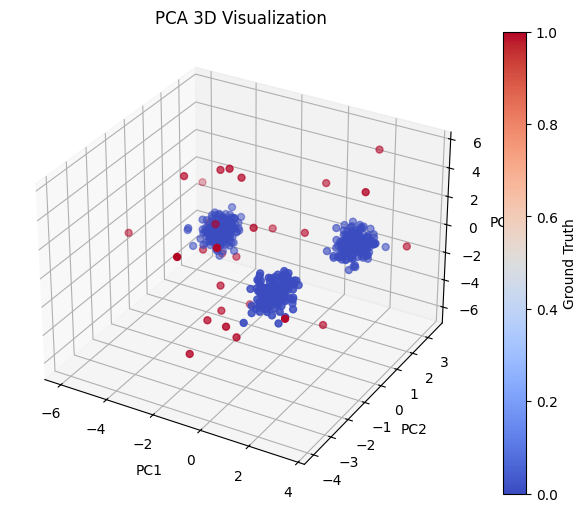

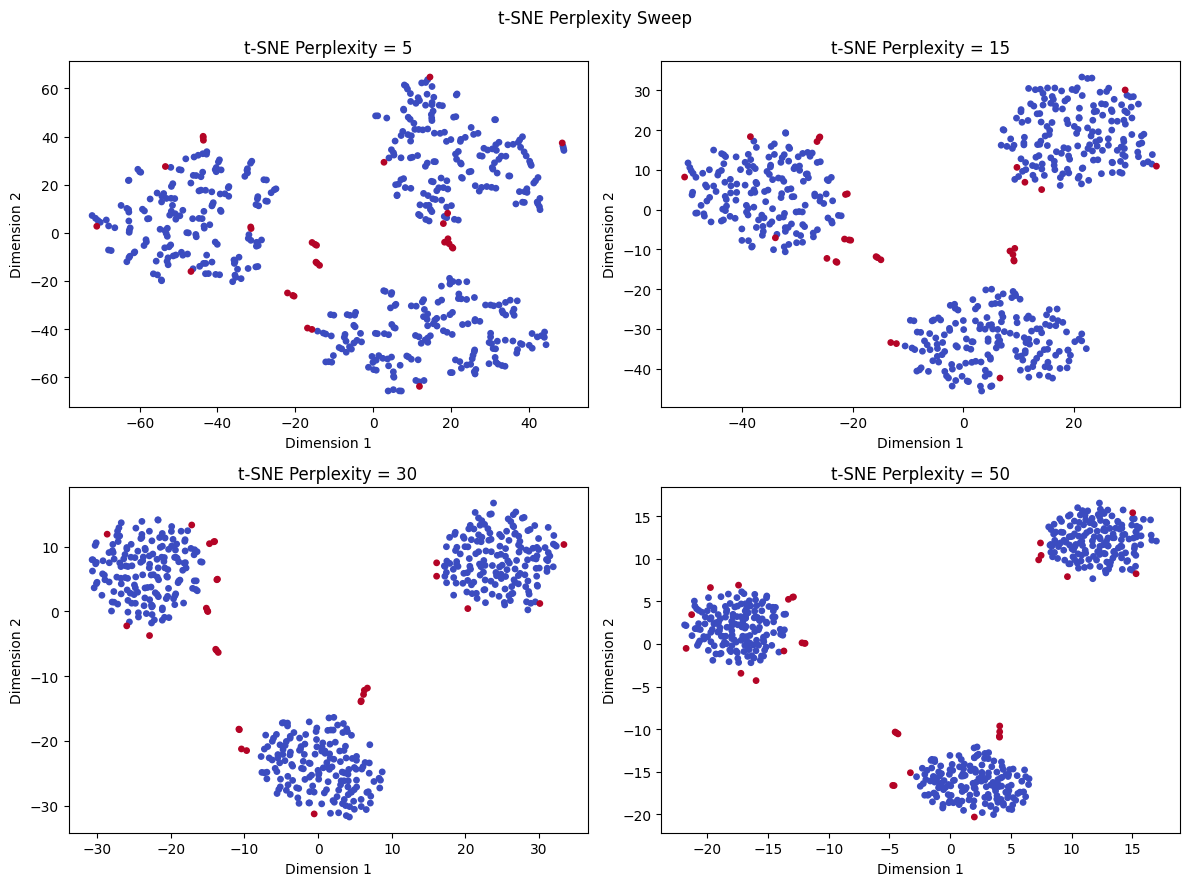

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

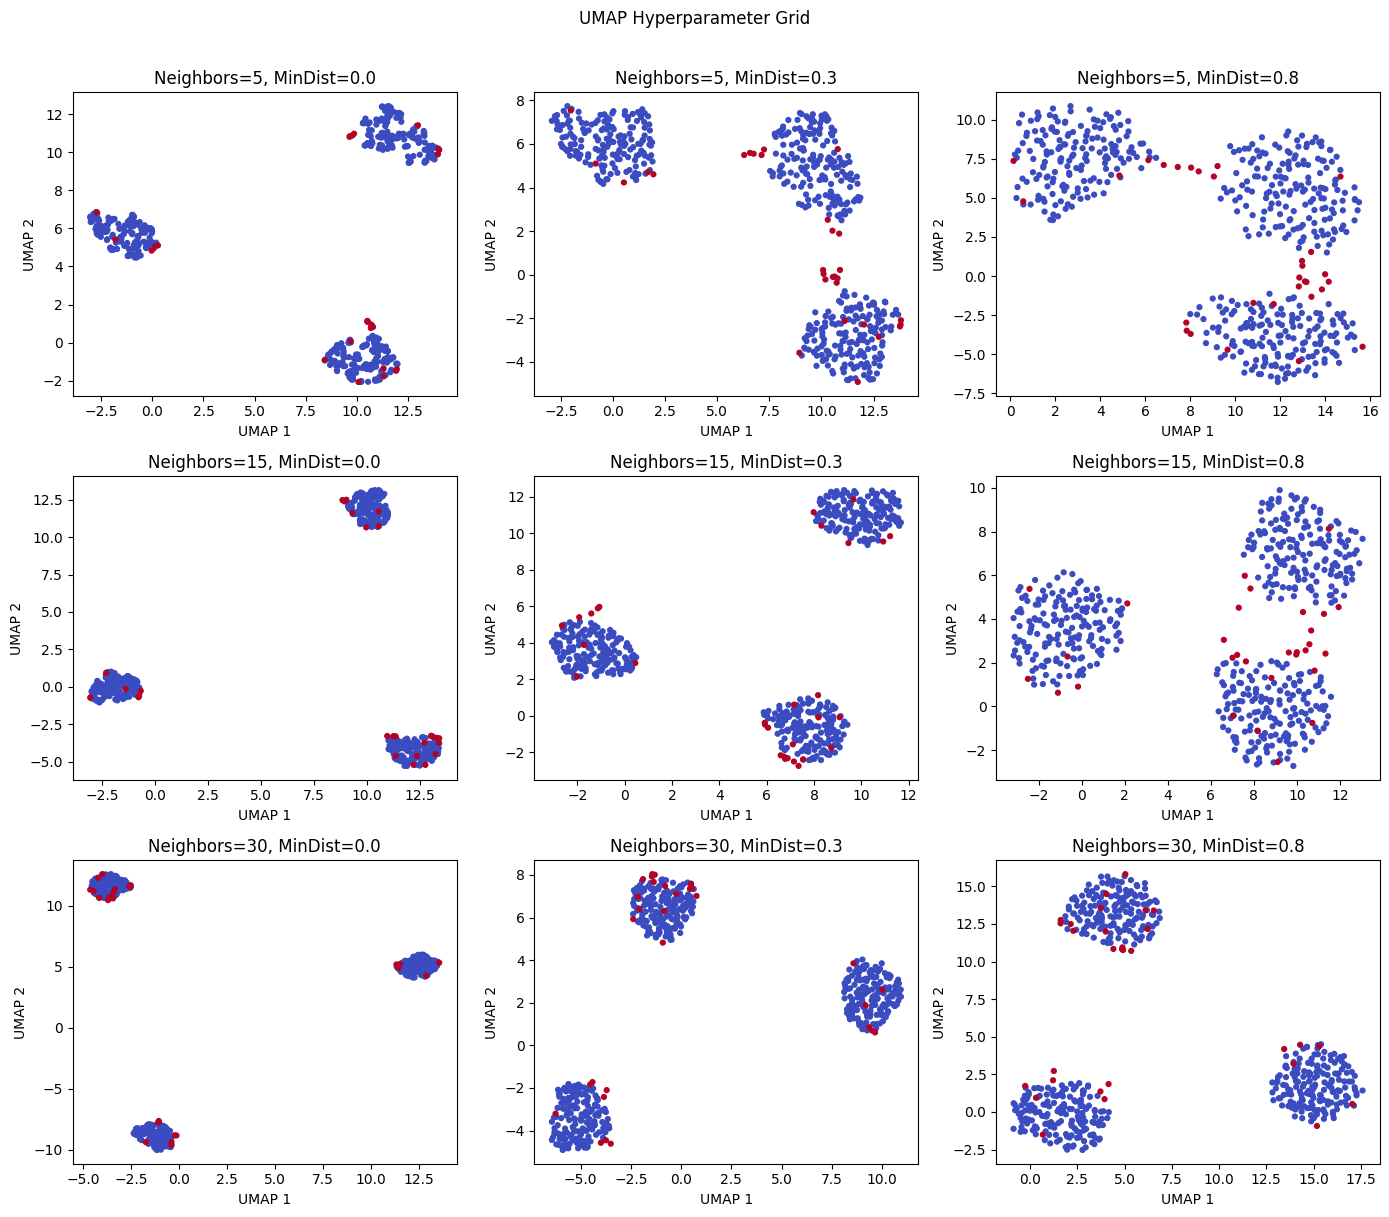


ISOLATION FOREST EVALUATION
Accuracy: 0.9962
Precision: 0.9667
Recall: 0.9667
F1 Score: 0.9667

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       500
     Anomaly       0.97      0.97      0.97        30

    accuracy                           1.00       530
   macro avg       0.98      0.98      0.98       530
weighted avg       1.00      1.00      1.00       530

Confusion Matrix:
[[499   1]
 [  1  29]]


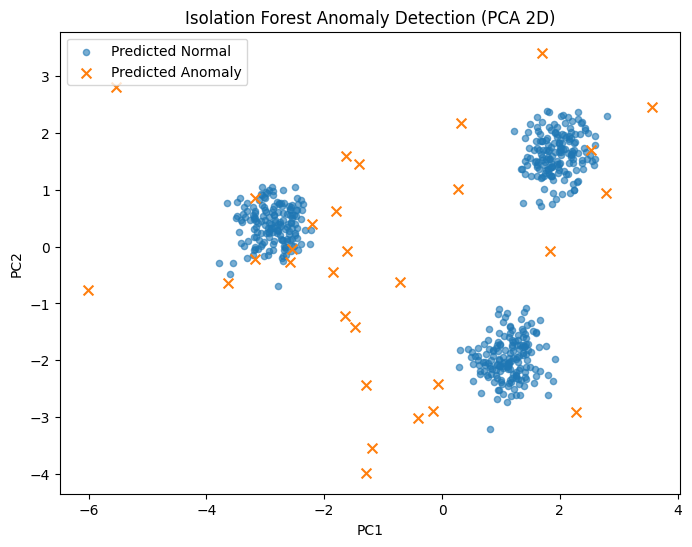


First 15 Ground Truth vs Predictions:
    Ground_Truth  Predicted_Anomaly
0              0                  0
1              0                  0
2              0                  0
3              0                  0
4              0                  0
5              0                  0
6              0                  0
7              0                  0
8              0                  0
9              0                  0
10             0                  0
11             0                  0
12             0                  0
13             0                  0
14             0                  0


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Dashboard saved successfully: dim_reduction_dashboard.png


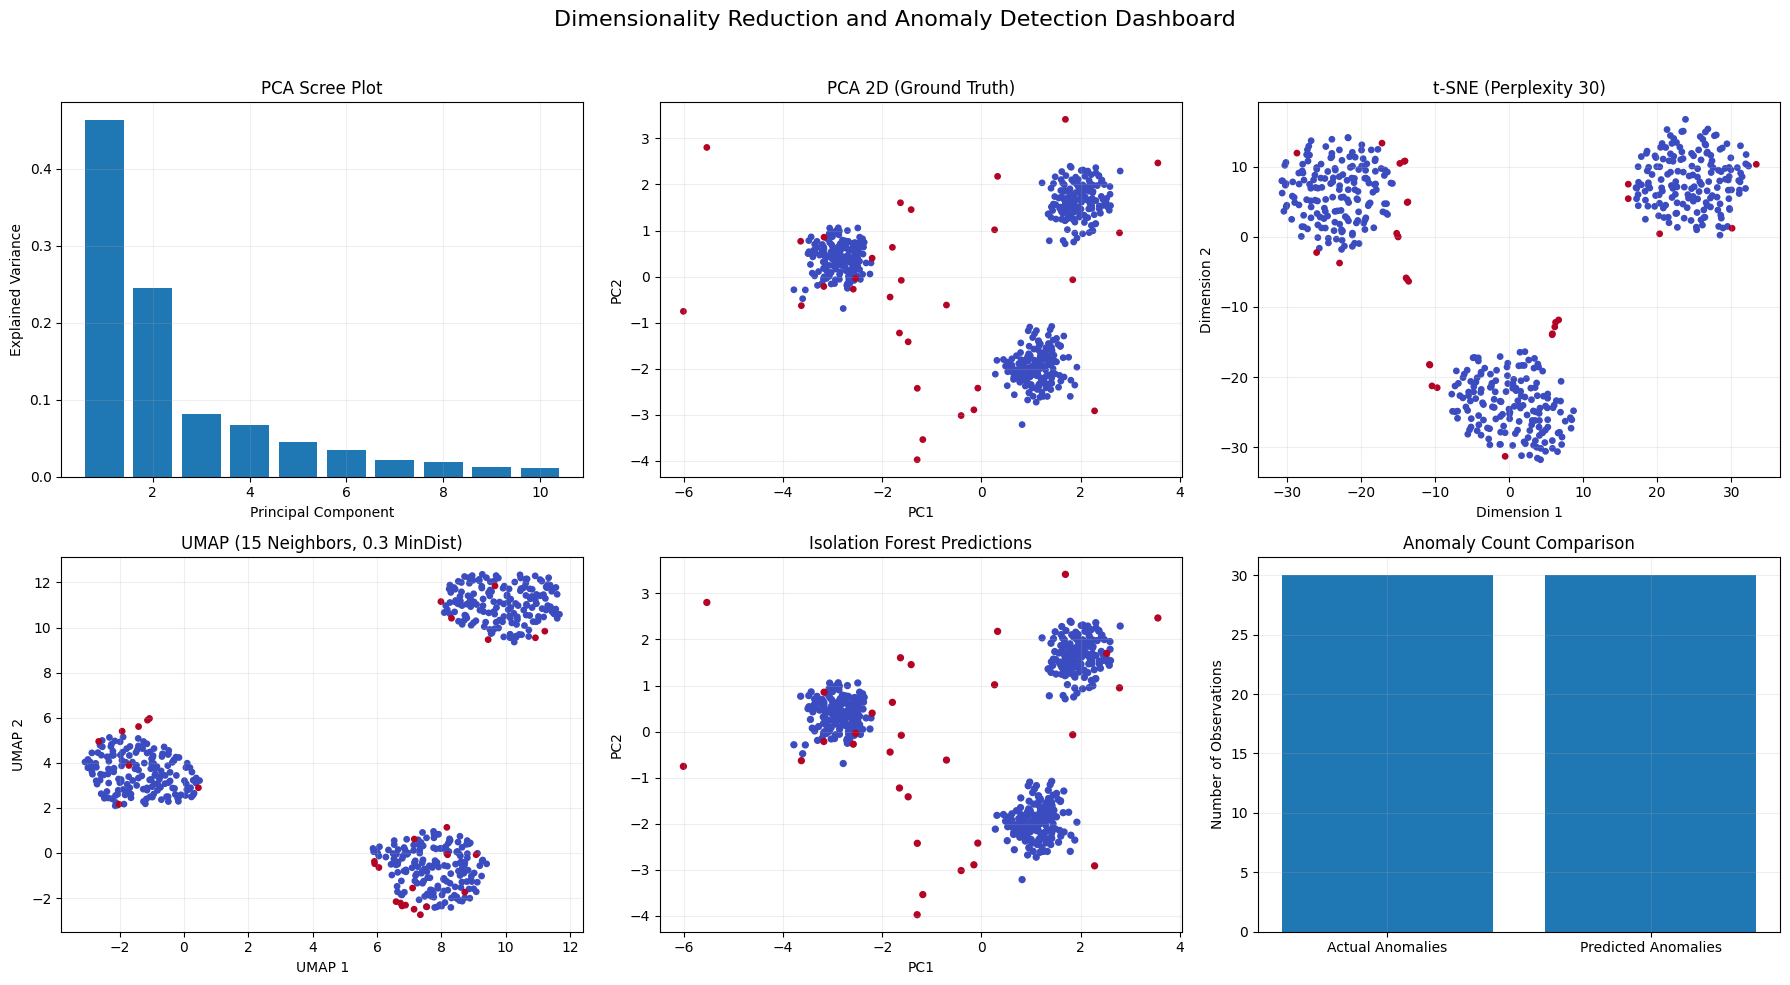


ALL TASKS COMPLETED SUCCESSFULLY!


In [ ]:

# ============================================================
# DIMENSIONALITY REDUCTION AND ANOMALY DETECTION DASHBOARD
# PCA + t-SNE + UMAP + Isolation Forest + PNG Dashboard
# ============================================================

# STEP 1: INSTALL UMAP
!pip -q install umap-learn

# STEP 2: IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from mpl_toolkits.mplot3d import Axes3D
import umap

# STEP 3: CREATE DATASET WITH GROUND-TRUTH ANOMALIES
np.random.seed(42)

# Generate normal observations
X_normal, _ = make_blobs(
    n_samples=500,
    centers=3,
    n_features=10,
    cluster_std=1.5,
    random_state=42
)

# Generate artificial anomalies far from normal clusters
X_anomalies = np.random.uniform(
    low=-15, high=15, size=(30, 10)
)

X = np.vstack([X_normal, X_anomalies])

# Ground truth: 0 = normal, 1 = anomaly
y_true = np.concatenate([
    np.zeros(len(X_normal), dtype=int),
    np.ones(len(X_anomalies), dtype=int)
])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X_scaled.shape)
print("Normal observations:", np.sum(y_true == 0))
print("True anomalies:", np.sum(y_true == 1))


# ============================================================
# 1. PCA SCREE PLOT + 2D + 3D VISUALIZATION
# ============================================================

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(explained) + 1), explained,
        alpha=0.7, label="Individual variance")
plt.plot(range(1, len(explained) + 1), cumulative,
         marker="o", label="Cumulative variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.legend()
plt.grid(True)
plt.show()

print("Variance explained by first 2 PCs:",
      round(cumulative[1] * 100, 2), "%")
print("Variance explained by first 3 PCs:",
      round(cumulative[2] * 100, 2), "%")

# PCA 2D
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
            c=y_true, cmap="coolwarm", s=25)
plt.title("PCA 2D Visualization")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Ground Truth (0=Normal, 1=Anomaly)")
plt.show()

# PCA 3D
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
    c=y_true, cmap="coolwarm", s=25
)
ax.set_title("PCA 3D Visualization")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
fig.colorbar(scatter, ax=ax, label="Ground Truth")
plt.show()


# ============================================================
# 2. t-SNE PERPLEXITY SWEEP
# ============================================================

# Each perplexity must be less than the number of samples.
perplexities = [5, 15, 30, 50]
tsne_results = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, perplexity in enumerate(perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    embedding = tsne.fit_transform(X_scaled)
    tsne_results[perplexity] = embedding

    axes[i].scatter(
        embedding[:, 0], embedding[:, 1],
        c=y_true, cmap="coolwarm", s=15
    )
    axes[i].set_title(f"t-SNE Perplexity = {perplexity}")
    axes[i].set_xlabel("Dimension 1")
    axes[i].set_ylabel("Dimension 2")

plt.suptitle("t-SNE Perplexity Sweep")
plt.tight_layout()
plt.show()


# ============================================================
# 3. UMAP HYPERPARAMETER GRID
# ============================================================

neighbors_values = [5, 15, 30]
min_dist_values = [0.0, 0.3, 0.8]

umap_results = {}
fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for i, n_neighbors in enumerate(neighbors_values):
    for j, min_dist in enumerate(min_dist_values):

        reducer = umap.UMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            random_state=42
        )

        embedding = reducer.fit_transform(X_scaled)

        umap_results[(n_neighbors, min_dist)] = embedding

        axes[i, j].scatter(
            embedding[:, 0], embedding[:, 1],
            c=y_true, cmap="coolwarm", s=12
        )

        axes[i, j].set_title(
            f"Neighbors={n_neighbors}, MinDist={min_dist}"
        )
        axes[i, j].set_xlabel("UMAP 1")
        axes[i, j].set_ylabel("UMAP 2")

plt.suptitle("UMAP Hyperparameter Grid", y=1.01)
plt.tight_layout()
plt.show()


# ============================================================
# 4. ISOLATION FOREST VS GROUND-TRUTH ANOMALIES
# ============================================================

contamination = len(X_anomalies) / len(X)

isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=contamination,
    random_state=42
)

# Isolation Forest returns 1 for normal and -1 for anomaly
raw_predictions = isolation_forest.fit_predict(X_scaled)

# Convert to 0 = normal, 1 = anomaly
y_pred = (raw_predictions == -1).astype(int)

print("\nISOLATION FOREST EVALUATION")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred), 4))
print("Recall:", round(recall_score(y_true, y_pred), 4))
print("F1 Score:", round(f1_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# PCA plot: show actual and detected anomalies
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca_2d[y_pred == 0, 0],
    X_pca_2d[y_pred == 0, 1],
    label="Predicted Normal",
    alpha=0.6,
    s=20
)

plt.scatter(
    X_pca_2d[y_pred == 1, 0],
    X_pca_2d[y_pred == 1, 1],
    label="Predicted Anomaly",
    marker="x",
    s=50
)

plt.title("Isolation Forest Anomaly Detection (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

# Compare ground truth and predictions
comparison = pd.DataFrame({
    "Ground_Truth": y_true,
    "Predicted_Anomaly": y_pred
})

print("\nFirst 15 Ground Truth vs Predictions:")
print(comparison.head(15))


# ============================================================
# 5. DIMENSION REDUCTION DASHBOARD PNG
# ============================================================

def dim_reduction_dashboard(
    X_scaled,
    y_true,
    y_pred,
    save_path="dim_reduction_dashboard.png"
):
    """
    Generate a six-panel dashboard and save it as a PNG.
    Returns the figure.
    """

    # PCA
    pca = PCA()
    pca_all = pca.fit_transform(X_scaled)
    pca_2 = pca_all[:, :2]

    # t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )
    tsne_2 = tsne.fit_transform(X_scaled)

    # UMAP
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.3,
        random_state=42
    )
    umap_2 = reducer.fit_transform(X_scaled)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Panel 1: PCA scree plot
    axes[0, 0].bar(
        range(1, len(pca.explained_variance_ratio_) + 1),
        pca.explained_variance_ratio_
    )
    axes[0, 0].set_title("PCA Scree Plot")
    axes[0, 0].set_xlabel("Principal Component")
    axes[0, 0].set_ylabel("Explained Variance")

    # Panel 2: PCA 2D
    axes[0, 1].scatter(
        pca_2[:, 0], pca_2[:, 1],
        c=y_true, cmap="coolwarm", s=15
    )
    axes[0, 1].set_title("PCA 2D (Ground Truth)")
    axes[0, 1].set_xlabel("PC1")
    axes[0, 1].set_ylabel("PC2")

    # Panel 3: t-SNE
    axes[0, 2].scatter(
        tsne_2[:, 0], tsne_2[:, 1],
        c=y_true, cmap="coolwarm", s=15
    )
    axes[0, 2].set_title("t-SNE (Perplexity 30)")
    axes[0, 2].set_xlabel("Dimension 1")
    axes[0, 2].set_ylabel("Dimension 2")

    # Panel 4: UMAP
    axes[1, 0].scatter(
        umap_2[:, 0], umap_2[:, 1],
        c=y_true, cmap="coolwarm", s=15
    )
    axes[1, 0].set_title("UMAP (15 Neighbors, 0.3 MinDist)")
    axes[1, 0].set_xlabel("UMAP 1")
    axes[1, 0].set_ylabel("UMAP 2")

    # Panel 5: Isolation Forest predictions
    axes[1, 1].scatter(
        pca_2[:, 0], pca_2[:, 1],
        c=y_pred, cmap="coolwarm", s=18
    )
    axes[1, 1].set_title("Isolation Forest Predictions")
    axes[1, 1].set_xlabel("PC1")
    axes[1, 1].set_ylabel("PC2")

    # Panel 6: Actual versus predicted anomaly counts
    counts = [
        int(np.sum(y_true == 1)),
        int(np.sum(y_pred == 1))
    ]

    axes[1, 2].bar(
        ["Actual Anomalies", "Predicted Anomalies"],
        counts
    )
    axes[1, 2].set_title("Anomaly Count Comparison")
    axes[1, 2].set_ylabel("Number of Observations")

    for ax in axes.flat:
        ax.grid(alpha=0.2)

    fig.suptitle(
        "Dimensionality Reduction and Anomaly Detection Dashboard",
        fontsize=16
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])

    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    print(f"Dashboard saved successfully: {save_path}")

    return fig


dashboard_fig = dim_reduction_dashboard(
    X_scaled,
    y_true,
    y_pred,
    save_path="dim_reduction_dashboard.png"
)

plt.show()

print("\nALL TASKS COMPLETED SUCCESSFULLY!")


In [ ]:

from google.colab import files

files.download("dim_reduction_dashboard.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Write dim_reduction_dashboard(X_scaled, y_labels, sample_n=1000) — PCA+t-SNE+UMAP 3-panel figure saved as
dim_reduction_dashboard.png

In [ ]:

!pip -q install umap-learn


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


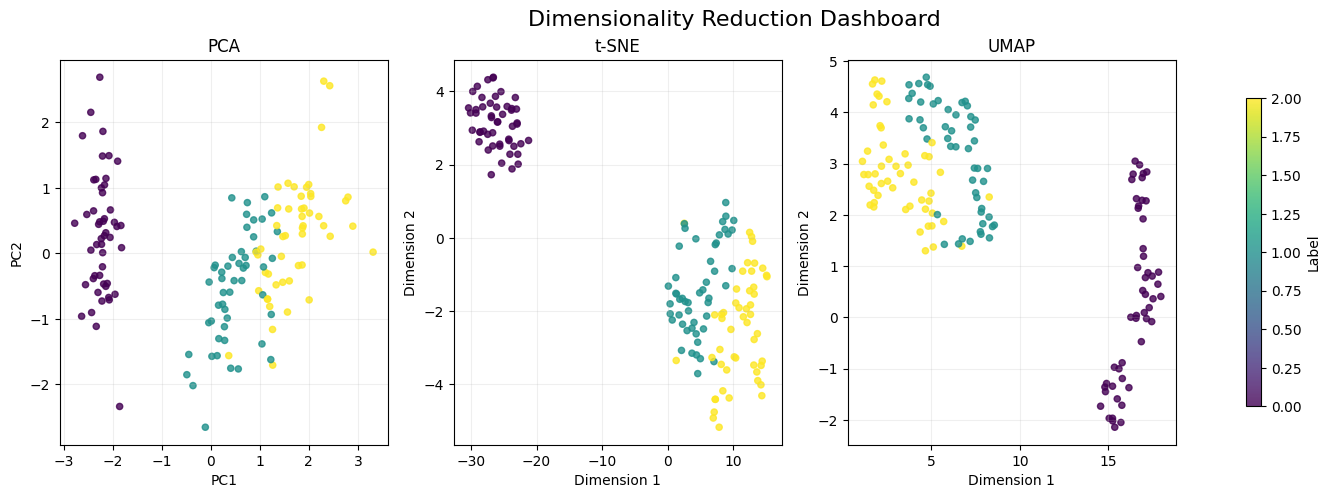

Saved: dim_reduction_dashboard.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap


def dim_reduction_dashboard(X_scaled, y_labels, sample_n=1000):
    X_scaled = np.asarray(X_scaled)
    y_labels = np.asarray(y_labels)

    # Sample data if the dataset is larger than sample_n
    n = min(sample_n, len(X_scaled))
    rng = np.random.default_rng(42)
    indices = rng.choice(len(X_scaled), size=n, replace=False)

    X_sample = X_scaled[indices]
    y_sample = y_labels[indices]

    # PCA: reduce to 2 dimensions
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_sample)

    # t-SNE: perplexity must be less than sample count
    perplexity = min(30, n - 1)
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )
    X_tsne = tsne.fit_transform(X_sample)

    # UMAP: reduce to 2 dimensions
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=min(15, n - 1),
        min_dist=0.3,
        random_state=42
    )
    X_umap = reducer.fit_transform(X_sample)

    # Create 3-panel figure
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    plots = [
        (X_pca, "PCA", "PC1", "PC2"),
        (X_tsne, "t-SNE", "Dimension 1", "Dimension 2"),
        (X_umap, "UMAP", "Dimension 1", "Dimension 2")
    ]

    for ax, (embedding, title, xlabel, ylabel) in zip(axes, plots):
        scatter = ax.scatter(
            embedding[:, 0],
            embedding[:, 1],
            c=y_sample,
            cmap="viridis",
            s=20,
            alpha=0.8
        )
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.2)

    fig.colorbar(
        scatter,
        ax=axes.tolist(),
        label="Label",
        shrink=0.8
    )

    fig.suptitle("Dimensionality Reduction Dashboard", fontsize=16)
    fig.savefig(
        "dim_reduction_dashboard.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    print("Saved: dim_reduction_dashboard.png")

    return fig


# Example dataset and execution
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)
y_labels = iris.target

dashboard = dim_reduction_dashboard(
    X_scaled, y_labels, sample_n=1000
)


In [ ]:

from google.colab import files

files.download("dim_reduction_dashboard.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>